# Chapter 12: Even Better Language Translation with Transformers!!!

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [2]:
first_language_words = ['<SOS>', 'eat', 'buy', 'sell', 'wash', 'cut', 'cook', 'apples', 'pears', 'plums', 'grapes', 'cherries', 'nuts']
second_language_words = ['<SOS>', 'mananca', 'cumpara', 'vinde', 'spala', 'taie', 'gateste', 'mere', 'pere', 'prune', 'struguri', 'cirese', 'nuci', '<EOS>']

verbs = [('eat', 'mananca'), ('buy', 'cumpara'), ('sell', 'vinde'), ('wash', 'spala'), ('cut', 'taie'), ('cook', 'gateste')]
objects = [('apples', 'mere'), ('pears', 'pere'), ('plums', 'prune'), ('grapes', 'struguri'), ('cherries', 'cirese'), ('nuts', 'nuci')]

train_data = []
test_data = []

for verb_index, (verb_first, verb_second) in enumerate(verbs):
    for object_index, (object_first, object_second) in enumerate(objects):
        pair = [f'<SOS> {verb_first} {object_first}', f'<SOS> {verb_second} {object_second} <EOS>']

        if verb_index == object_index:
            test_data.append(pair)
        else:
            train_data.append(pair)

first_language_word_count = len(first_language_words)
second_language_word_count = len(second_language_words)

def get_data_loader(data):
    X_raw = []
    y_raw = []
    
    for one_data in data:
        X_one_data = []
        words = one_data[0].split()
    
        for word in words:
            X_one_data.append(first_language_words.index(word))
            
        X_raw.append(X_one_data)
        
        y_one_data = []
        words = one_data[1].split()
        
        for word in words:
            y_one_data.append(second_language_words.index(word))
            
        y_raw.append(y_one_data)
    
    X_tensor = torch.tensor(X_raw).int()
    y_tensor = torch.tensor(y_raw).int()
    
    tensor_data = TensorDataset(X_tensor, y_tensor)
    data_loader = DataLoader(tensor_data, shuffle=True)
    
    return data_loader

train_data_loader = get_data_loader(train_data)
test_data_loader = get_data_loader(test_data)

In [3]:
second_language_sos = second_language_words.index('<SOS>')
second_language_eos = second_language_words.index('<EOS>')
embedding_dim = 8
qkv_dim = 8
attention_heads_nr = 2
nn_dim = 4 * embedding_dim
enc_layers_nr = 2
dec_layers_nr = 2

class EncDecNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.enc_embedding = nn.Embedding(num_embeddings=first_language_word_count, embedding_dim=embedding_dim)
        self.enc_queries = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(enc_layers_nr)
        ])
        self.enc_keys = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(enc_layers_nr)
        ])
        self.enc_values = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(enc_layers_nr)
        ])
        self.enc_fcs = nn.ModuleList([nn.Linear(qkv_dim * attention_heads_nr, embedding_dim) for _ in range(enc_layers_nr)])
        self.enc_nns =  nn.ModuleList([nn.Sequential(
            nn.Linear(embedding_dim, nn_dim),
            nn.ReLU(),
            nn.Linear(nn_dim, embedding_dim)
        ) for _ in range(enc_layers_nr)])
        
        self.dec_embedding = nn.Embedding(num_embeddings=second_language_word_count, embedding_dim=embedding_dim)
        self.dec_queries = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.dec_keys = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.dec_values = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.dec_fcs =  nn.ModuleList([nn.Linear(qkv_dim * attention_heads_nr, embedding_dim) for _ in range(dec_layers_nr)])
    
        self.enc_dec_queries = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.enc_dec_keys = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.enc_dec_values = nn.ModuleList([
            nn.ModuleList([nn.Linear(qkv_dim, qkv_dim) for _ in range(attention_heads_nr)])
            for _ in range(dec_layers_nr)
        ])
        self.enc_dec_fcs =  nn.ModuleList([nn.Linear(qkv_dim * attention_heads_nr, embedding_dim) for _ in range(dec_layers_nr)])
        self.enc_dec_nns =  nn.ModuleList([nn.Sequential(
            nn.Linear(embedding_dim, nn_dim),
            nn.ReLU(),
            nn.Linear(nn_dim, embedding_dim)
        ) for _ in range(dec_layers_nr)])
        
        self.enc_dec_linear = nn.Linear(embedding_dim, second_language_word_count)
    
    @staticmethod
    def get_positional_encoding(x_param):
        token_positions = torch.arange(len(x_param)).unsqueeze(dim = 1)
        dimension_indices = torch.arange(0, embedding_dim, 2)
        frequencies = 1 / (10000 ** (dimension_indices / embedding_dim))
    
        positional_encoding = torch.zeros(len(x_param), embedding_dim)
        positional_encoding[:, 0::2] = torch.sin(token_positions * frequencies)
        positional_encoding[:, 1::2] = torch.cos(token_positions * frequencies)
    
        return positional_encoding

    @staticmethod
    def standardize(value):
        means = value.mean(dim=1, keepdim=True)
        standard_deviations = value.std(dim=1, keepdim=True)

        return (value - means) / standard_deviations

    def get_encoded_values(self, x_param, embedding_func):
        word_embedding = embedding_func(x_param[0])
        positional_encoding = self.get_positional_encoding(x_param[0])
        encoded_values = self.standardize(word_embedding + positional_encoding)

        return encoded_values
        
    @staticmethod
    def get_attention(query_param, key_param, value_param, mask_param=None):
        softmax_input = (torch.matmul(query_param, key_param.T)) / torch.sqrt(torch.tensor(qkv_dim))

        if mask_param is not None:
            softmax_input = softmax_input + mask_param
        
        return torch.matmul(torch.softmax(softmax_input, dim=1), value_param)
        
    def get_enc_output(self, x_first_language):
        enc_output = self.get_encoded_values(x_first_language, self.enc_embedding)
        
        for enc_layer_index in range(enc_layers_nr):
            enc_attentions = torch.tensor([])
            
            for attention_head_index in range(attention_heads_nr):
                enc_queries = self.enc_queries[enc_layer_index][attention_head_index](enc_output)
                enc_keys = self.enc_keys[enc_layer_index][attention_head_index](enc_output)
                enc_values = self.enc_values[enc_layer_index][attention_head_index](enc_output)
                enc_attention = self.get_attention(enc_queries, enc_keys, enc_values)
                enc_attentions = torch.cat((enc_attentions, enc_attention), dim=1)
                
            enc_output = enc_output + self.enc_fcs[enc_layer_index](enc_attentions)
            enc_output = self.standardize(enc_output)
            enc_output = self.enc_nns[enc_layer_index](enc_output)
            
        return enc_output
        
    def get_enc_dec_output(self, x_second_language, enc_output):
        second_language_words_nr = len(x_second_language[0])
        enc_dec_output = self.get_encoded_values(x_second_language, self.dec_embedding)
        
        for dec_layer_index in range(dec_layers_nr):
            dec_attentions = torch.tensor([])
            
            for attention_head_index in range(attention_heads_nr):
                dec_queries = self.dec_queries[dec_layer_index][attention_head_index](enc_dec_output)
                dec_keys = self.dec_keys[dec_layer_index][attention_head_index](enc_dec_output)
                dec_values = self.dec_values[dec_layer_index][attention_head_index](enc_dec_output)
                dec_mask = torch.triu(torch.full((second_language_words_nr, second_language_words_nr), -torch.inf), diagonal=1)
                dec_attention = self.get_attention(dec_queries, dec_keys, dec_values, dec_mask)
                dec_attentions = torch.cat((dec_attentions, dec_attention), dim=1)
            
            dec_output = enc_dec_output + self.dec_fcs[dec_layer_index](dec_attentions)
            dec_output = self.standardize(dec_output)
            
            enc_dec_attentions = torch.tensor([])
            
            for attention_head_index in range(attention_heads_nr):
                enc_dec_queries = self.enc_dec_queries[dec_layer_index][attention_head_index](dec_output)
                enc_dec_keys = self.enc_dec_keys[dec_layer_index][attention_head_index](enc_output)
                enc_dec_values = self.enc_dec_values[dec_layer_index][attention_head_index](enc_output)
                enc_dec_attention = self.get_attention(enc_dec_queries, enc_dec_keys, enc_dec_values)
                enc_dec_attentions = torch.cat((enc_dec_attentions, enc_dec_attention), dim=1)
            
            enc_dec_output = dec_output + self.enc_dec_fcs[dec_layer_index](enc_dec_attentions)
            enc_dec_output = self.enc_dec_nns[dec_layer_index](enc_dec_output)
            
        return enc_dec_output
        
    def forward(self, x_first_language, x_second_language, teacher_forcing=True):
        enc_output = self.get_enc_output(x_first_language)
    
        if teacher_forcing:
            enc_dec_output = self.get_enc_dec_output(x_second_language, enc_output)
            
            return self.enc_dec_linear(enc_dec_output)
        else:
            max_steps = 3
            current_step = 0
            predicted_second_language_words = torch.tensor([[second_language_sos]])
            
            while True:
                enc_dec_output = self.get_enc_dec_output(predicted_second_language_words, enc_output)
                argmax_input = self.enc_dec_linear(enc_dec_output)

                new_second_language_word = torch.argmax(argmax_input, dim=1)[-1]
                predicted_second_language_words = torch.cat((predicted_second_language_words, torch.tensor([[new_second_language_word]])), dim=1)

                current_step += 1

                if current_step == max_steps or new_second_language_word == second_language_eos:
                    break
                    
            return predicted_second_language_words.int()

In [4]:
enc_dec_net = EncDecNet()
optimizer = torch.optim.Adam(enc_dec_net.parameters(), weight_decay=1e-3)
loss_func = torch.nn.CrossEntropyLoss()
losses = []

enc_dec_net.train()

for epoch in range(500):
    for X, y in train_data_loader:
        y_pred = enc_dec_net(X, y[:, :-1])

        y_pred_target = y_pred
        y_target = y[:, 1:].squeeze().long()
        
        loss = loss_func(y_pred_target, y_target)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.detach().item())

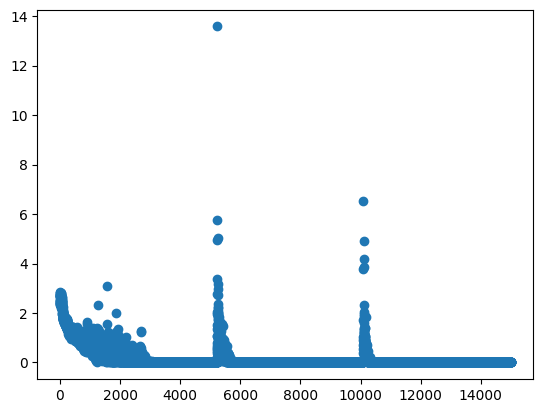

In [5]:
plt.scatter(range(len(losses)), losses)
plt.show()

In [6]:
enc_dec_net.eval()

for X, y in train_data_loader:
    y_pred = enc_dec_net(X, _, teacher_forcing=False)

    print(y)
    print(y_pred)
    print('---------------')

tensor([[ 0,  5,  7, 13]], dtype=torch.int32)
tensor([[ 0,  5,  7, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  5,  9, 13]], dtype=torch.int32)
tensor([[ 0,  5,  9, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  1, 11, 13]], dtype=torch.int32)
tensor([[ 0,  1, 11, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  4, 11, 13]], dtype=torch.int32)
tensor([[ 0,  4, 11, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  4, 12, 13]], dtype=torch.int32)
tensor([[ 0,  4, 12, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  1,  9, 13]], dtype=torch.int32)
tensor([[ 0,  1,  9, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  6,  7, 13]], dtype=torch.int32)
tensor([[ 0,  6,  7, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  2, 12, 13]], dtype=torch.int32)
tensor([[ 0,  2, 12, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  3, 12, 13]], dtype=torch.int32)
tensor([[ 0,  3, 12, 13]], dtype=torch.int32)
---------------
tensor([[ 0,  4,  8, 13]], d

In [7]:
def format_prediction(X_param, y_param, y_pred_param):
    special_tokens = {'<SOS>', '<EOS>'}

    def to_words(indices, vocabulary):
        return ' '.join(vocabulary[index] for index in indices[0].tolist() if vocabulary[index] not in special_tokens)

    source = to_words(X_param, first_language_words)
    predicted = to_words(y_pred_param, second_language_words)
    correct = to_words(y_param, second_language_words)
    marker = '' if predicted == correct else f' (correct translation: {correct})'

    return f'{source} -> {predicted}{marker}'

In [8]:
for X, y in test_data_loader:
    y_pred = enc_dec_net(X, _, teacher_forcing=False)

    print(format_prediction(X, y, y_pred))

cut cherries -> taie cirese
sell plums -> vinde prune
buy pears -> cumpara pere
cook nuts -> mananca nuci (correct translation: gateste nuci)
eat apples -> mananca mere
wash grapes -> spala struguri
